### Q1

In [1]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.tokenize import sent_tokenize, word_tokenize

required_nltk_resources = ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]
for resource in required_nltk_resources:
    if not nltk.download(resource, quiet=True):
        raise RuntimeError(f"Could not download required NLTK resource: {resource}")

text = """Johann Wolfgang von Geothe inspires me a lot. He was one of the Great writers of the German world with his works on par with the works of Shakespeare and capturing the essence of human condition or the condition of your soul ingeniously in his works. Shakespeare was a writer but Goethe was a polymath genious, a brilliant Statesman, Researcher, Writer and owner of an ecxeptional intellect seen rarely. He had an encyclopaeic knowledge of the western culure as a whole and a brilliant grasp of the intellectuals tendencies rooted in those Literary traditions; his work Faust is full of references to the western intellectual tradition, Faust is a dense work of literature spanning over 12000 lines of poetry/ballad that requires the careful attention and warrants serious long term dedication. On the other hard his other work \"The sorrows of young Werther\" is a very short punchy read that can be finished over a weekend. The emotional impact of both of them is profound even with grave differences in their length and style."""

lowercase_text = text.lower()
clean_text = re.sub(r"[^\w\s]", " ", lowercase_text)
clean_text = " ".join(clean_text.split())
sentences = sent_tokenize(text)
python_split_tokens = lowercase_text.split()
nltk_tokens_original = word_tokenize(lowercase_text)
tokens = word_tokenize(clean_text)
english_stopwords = set(stopwords.words("english"))
filtered_tokens = [token for token in tokens if token.isalpha() and token not in english_stopwords]
frequency_distribution = FreqDist(filtered_tokens)

print("Lowercase text with punctuation removed:")
print(clean_text)
print(f"\nSentence count: {len(sentences)}")
for number, sentence in enumerate(sentences, start=1):
    print(f"{number}. {sentence}")
print(f"\nPython split() token count: {len(python_split_tokens)}")
print(f"NLTK word_tokenize() token count: {len(nltk_tokens_original)}")
print("Python split() sample:", python_split_tokens[:24])
print("NLTK word_tokenize() sample:", nltk_tokens_original[:24])
print("\nAfter punctuation removal, split() and word_tokenize() produce the same tokens:", clean_text.split() == tokens)
print(f"\nTokens after NLTK stopword removal: {len(filtered_tokens)}")
print("Word frequency distribution excluding stopwords:")
for word, count in frequency_distribution.most_common():
    print(f"{word}: {count}")

[nltk_data] Error loading punkt: <urlopen error [WinError 10054] An
[nltk_data]     existing connection was forcibly closed by the remote
[nltk_data]     host>


RuntimeError: Could not download required NLTK resource: punkt

### Q2

In [ ]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

alphabetic_words = re.findall(r"[A-Za-z]+", text.lower())
q2_words = [word for word in alphabetic_words if word not in english_stopwords]
porter = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stemmed_words = [porter.stem(word) for word in q2_words]
lemmatized_words = [lemmatizer.lemmatize(word) for word in q2_words]

print(f"Alphabetic words after stopword removal: {len(q2_words)}")
print("Original | stemmed | lemmatized (first 40 tokens)")
for original, stemmed, lemmatized in zip(q2_words[:40], stemmed_words[:40], lemmatized_words[:40]):
    print(f"{original:18} | {stemmed:14} | {lemmatized}")
print("\nStemming reduces words mechanically and is useful when compact matching matters more than grammatical form.")
print("Lemmatization returns dictionary forms and is preferable when readable, linguistically meaningful terms matter; this default lemmatizer treats words as nouns.")

Alphabetic words after stopword removal: 90
Original | stemmed | lemmatized (first 40 tokens)
johann             | johann         | johann
wolfgang           | wolfgang       | wolfgang
von                | von            | von
geothe             | geoth          | geothe
inspires           | inspir         | inspires
lot                | lot            | lot
one                | one            | one
great              | great          | great
writers            | writer         | writer
german             | german         | german
world              | world          | world
works              | work           | work
par                | par            | par
works              | work           | work
shakespeare        | shakespear     | shakespeare
capturing          | captur         | capturing
essence            | essenc         | essence
human              | human          | human
condition          | condit         | condition
condition          | condit         | condition
soul  

### Q3

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

short_texts = [
    "Solar panels convert sunlight into clean electricity for homes and communities.",
    "Wind turbines use moving air to produce renewable electricity across open landscapes.",
    "Battery storage saves clean energy and supplies electricity when solar and wind output falls."
]

count_vectorizer = CountVectorizer(stop_words="english")
count_matrix = count_vectorizer.fit_transform(short_texts)
count_terms = count_vectorizer.get_feature_names_out()
print("Bag of Words term order:", count_terms.tolist())
for document_number, row in enumerate(count_matrix.toarray(), start=1):
    print(f"Text {document_number} counts:", dict(zip(count_terms, row.tolist())))

tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(short_texts)
tfidf_terms = tfidf_vectorizer.get_feature_names_out()
print("\nTop three TF-IDF keywords per text:")
for document_number, row in enumerate(tfidf_matrix.toarray(), start=1):
    top_indices = row.argsort()[::-1][:3]
    top_keywords = [(tfidf_terms[index], round(float(row[index]), 3)) for index in top_indices]
    print(f"Text {document_number}: {top_keywords}")
print("\nInterpretation: terms with high TF-IDF scores are frequent in one text but less common across this three-text collection, so they distinguish each renewable-energy topic.")

Bag of Words term order: ['air', 'battery', 'clean', 'communities', 'convert', 'electricity', 'energy', 'falls', 'homes', 'landscapes', 'moving', 'open', 'output', 'panels', 'produce', 'renewable', 'saves', 'solar', 'storage', 'sunlight', 'supplies', 'turbines', 'use', 'wind']
Text 1 counts: {'air': 0, 'battery': 0, 'clean': 1, 'communities': 1, 'convert': 1, 'electricity': 1, 'energy': 0, 'falls': 0, 'homes': 1, 'landscapes': 0, 'moving': 0, 'open': 0, 'output': 0, 'panels': 1, 'produce': 0, 'renewable': 0, 'saves': 0, 'solar': 1, 'storage': 0, 'sunlight': 1, 'supplies': 0, 'turbines': 0, 'use': 0, 'wind': 0}
Text 2 counts: {'air': 1, 'battery': 0, 'clean': 0, 'communities': 0, 'convert': 0, 'electricity': 1, 'energy': 0, 'falls': 0, 'homes': 0, 'landscapes': 1, 'moving': 1, 'open': 1, 'output': 0, 'panels': 0, 'produce': 1, 'renewable': 1, 'saves': 0, 'solar': 0, 'storage': 0, 'sunlight': 0, 'supplies': 0, 'turbines': 1, 'use': 1, 'wind': 1}
Text 3 counts: {'air': 0, 'battery': 1, 'c

### Q4

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

technology_texts = [
    "Artificial intelligence learns patterns from data.\nAI systems classify images and understand language.\nMachine learning supports recommendations and predictions.\nThese tools help users automate decisions and find information.\nResponsible AI requires careful testing and human oversight.",
    "Blockchain stores digital records and data across a network.\nUsers share transactions on a distributed ledger.\nCryptographic methods help keep information secure.\nSmart contracts can automate agreed business rules.\nThis technology supports transparent tracking and reliable records."
]

technology_tokens = []
for number, description in enumerate(technology_texts, start=1):
    normalized_description = re.sub(r"[^a-z\s]", " ", description.lower())
    description_tokens = word_tokenize(normalized_description)
    content_tokens = [word for word in description_tokens if word not in english_stopwords]
    technology_tokens.append(content_tokens)
    print(f"Technology {number} tokens:", content_tokens)

token_sets = [set(tokens_for_text) for tokens_for_text in technology_tokens]
jaccard_similarity = len(token_sets[0] & token_sets[1]) / len(token_sets[0] | token_sets[1])
technology_tfidf = TfidfVectorizer(stop_words="english")
technology_matrix = technology_tfidf.fit_transform(technology_texts)
cosine_score = float(cosine_similarity(technology_matrix[0:1], technology_matrix[1:2])[0, 0])

print(f"\nJaccard similarity: {jaccard_similarity:.3f}")
print(f"Cosine similarity (TF-IDF): {cosine_score:.3f}")
print("Jaccard treats every distinct content word equally and is easy to interpret as shared vocabulary over combined vocabulary. TF-IDF cosine also uses term frequency and downweights words common across documents; for these short descriptions it gives a graded measure, but neither score recognizes that different technical terms may be conceptually related.")

Technology 1 tokens: ['artificial', 'intelligence', 'learns', 'patterns', 'data', 'ai', 'systems', 'classify', 'images', 'understand', 'language', 'machine', 'learning', 'supports', 'recommendations', 'predictions', 'tools', 'help', 'users', 'automate', 'decisions', 'find', 'information', 'responsible', 'ai', 'requires', 'careful', 'testing', 'human', 'oversight']
Technology 2 tokens: ['blockchain', 'stores', 'digital', 'records', 'data', 'across', 'network', 'users', 'share', 'transactions', 'distributed', 'ledger', 'cryptographic', 'methods', 'help', 'keep', 'information', 'secure', 'smart', 'contracts', 'automate', 'agreed', 'business', 'rules', 'technology', 'supports', 'transparent', 'tracking', 'reliable', 'records']

Jaccard similarity: 0.115
Cosine similarity (TF-IDF): 0.110
Jaccard treats every distinct content word equally and is easy to interpret as shared vocabulary over combined vocabulary. TF-IDF cosine also uses term frequency and downweights words common across document

### Q5

Positive | polarity=+0.300 | subjectivity=0.528 | The headphones sound clear, feel comfortable, and the battery lasts all day.
Positive | polarity=+0.167 | subjectivity=0.429 | Setup was simple and the helpful support team solved my issue quickly.
Negative | polarity=-0.700 | subjectivity=0.660 | This product is awful, terrible, disappointing, broken, and useless.
Negative | polarity=-0.350 | subjectivity=0.750 | Delivery was late and customer service was frustrating and unhelpful.
Neutral  | polarity=+0.000 | subjectivity=1.000 | The package arrived yesterday; I have only used the product once.


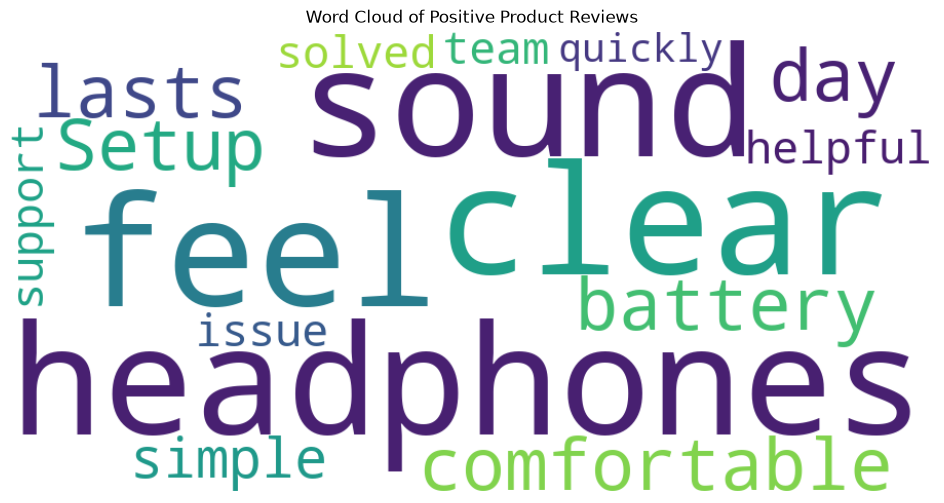

In [ ]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "The headphones sound clear, feel comfortable, and the battery lasts all day.",
    "Setup was simple and the helpful support team solved my issue quickly.",
    "This product is awful, terrible, disappointing, broken, and useless.",
    "Delivery was late and customer service was frustrating and unhelpful.",
    "The package arrived yesterday; I have only used the product once."
]

positive_reviews = []
for review in reviews:
    sentiment = TextBlob(review).sentiment
    if sentiment.polarity > 0.1:
        label = "Positive"
    elif sentiment.polarity < -0.1:
        label = "Negative"
    else:
        label = "Neutral"
    print(f"{label:8} | polarity={sentiment.polarity:+.3f} | subjectivity={sentiment.subjectivity:.3f} | {review}")
    if label == "Positive":
        positive_reviews.append(review)

if not positive_reviews:
    raise ValueError("No positive reviews were classified, so a positive-review word cloud cannot be generated.")

positive_review_text = " ".join(positive_reviews)
positive_wordcloud = WordCloud(width=900, height=450, background_color="white", random_state=42).generate(positive_review_text)
plt.figure(figsize=(12, 6))
plt.imshow(positive_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Product Reviews")
plt.show()

### Q6

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Embedding, Input, LSTM

training_text = """Renewable energy is changing how communities produce electricity. Solar panels capture sunlight on rooftops and in fields. Wind turbines convert moving air into power for homes and businesses. These sources create electricity without burning fossil fuels during operation. Batteries can store extra energy and release it when demand rises. Smart grids balance supply from different sources across a region. Engineers improve panels, turbines, and batteries to make clean power more affordable. Local projects can create skilled jobs and strengthen energy security. People can also save energy by improving insulation and choosing efficient appliances. Together, innovation and careful planning help communities build a reliable low carbon future."""

tf.keras.utils.set_random_seed(42)
print(f"Training paragraph word count: {len(re.findall(r'[A-Za-z]+', training_text))}")

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
sentence_token_sequences = tokenizer.texts_to_sequences(sent_tokenize(training_text))
input_sequences = []
for sentence_sequence in sentence_token_sequences:
    input_sequences.extend([sentence_sequence[:index + 1] for index in range(1, len(sentence_sequence))])
maximum_sequence_length = max(len(sequence) for sequence in input_sequences)
padded_sequences = pad_sequences(input_sequences, maxlen=maximum_sequence_length, padding="pre")
features = padded_sequences[:, :-1]
targets = padded_sequences[:, -1]
vocabulary_size = len(tokenizer.word_index) + 1

model = Sequential([
    Input(shape=(maximum_sequence_length - 1,)),
    Embedding(input_dim=vocabulary_size, output_dim=32),
    LSTM(64),
    Dense(32, activation="relu"),
    Dense(vocabulary_size, activation="softmax")
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
training_history = model.fit(features, targets, epochs=200, batch_size=8, verbose=0)
print(f"Training examples: {len(features)}; vocabulary size: {vocabulary_size}")
print(f"Final training accuracy: {training_history.history['accuracy'][-1]:.3f}")

def generate_line(seed_word, words_to_generate=12):
    generated_indices = tokenizer.texts_to_sequences([seed_word])[0]
    if not generated_indices:
        raise ValueError(f"Seed word is not in the training vocabulary: {seed_word}")
    for _ in range(words_to_generate):
        padded_seed = pad_sequences([generated_indices], maxlen=maximum_sequence_length - 1, padding="pre")
        probabilities = model.predict(padded_seed, verbose=0)[0]
        probabilities[0] = 0
        next_index = int(np.argmax(probabilities))
        if next_index == 0:
            break
        generated_indices.append(next_index)
    return " ".join(tokenizer.index_word[index] for index in generated_indices)

seed_words = ["renewable", "solar", "batteries"]
print("\nGenerated lines from the provided seed words:")
for line_number, seed_word in enumerate(seed_words, start=1):
    print(f"{line_number}. {generate_line(seed_word)}")

Training paragraph word count: 106
Training examples: 96; vocabulary size: 87
Final training accuracy: 1.000

Generated lines from the provided seed words:
1. renewable energy is changing how communities produce electricity fossil fuels operation future future
2. solar panels capture sunlight on rooftops and in fields fields demand reliable future
3. batteries can store extra energy and release it when demand rises low future
